In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
df = pd.read_csv("csv/dataset_completo_corregido.csv")
# Eliminar todas las columnas comp_*
columnas_comp = [
    c for c in df.columns
    if c.startswith("comp_")
]

df_sin_comp = df.drop(columns=columnas_comp)

print(df_sin_comp.shape)
print(df_sin_comp.columns.tolist())

df_sin_comp.to_csv("csv/dataset_sin_comp.csv", index=False)

(23993, 37)
['img_original', 'img_recodificada', 'metodo', 'formato_entrada', 'formato_salida', 'calidad', 'orig_rango', 'orig_std', 'orig_michelson', 'orig_hf', 'orig_lf', 'orig_hlfr', 'orig_edges_s1', 'orig_edges_s2', 'orig_edges_s3', 'orig_grad_mean', 'orig_grad_std', 'orig_glcm_contrast', 'orig_glcm_hom', 'orig_glcm_energy', 'orig_glcm_corr', 'orig_sat_mean', 'orig_sat_var', 'orig_hist', 'orig_hist_norm', 'orig_hist_bins', 'orig_hist_entropy', 'orig_hist_std', 'orig_hist_mean', 'orig_hist_min', 'orig_hist_max', 'orig_hist_skew', 'orig_hist_kurt', 'ms_ssim', 'lpips_raw', 'lpips_norm', 'combinado']


In [4]:
df = pd.read_csv("csv/dataset_sin_comp.csv")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23993 entries, 0 to 23992
Data columns (total 37 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   img_original        23993 non-null  object 
 1   img_recodificada    23993 non-null  object 
 2   metodo              23993 non-null  object 
 3   formato_entrada     23993 non-null  object 
 4   formato_salida      23993 non-null  object 
 5   calidad             23993 non-null  int64  
 6   orig_rango          23993 non-null  float64
 7   orig_std            23993 non-null  float64
 8   orig_michelson      23993 non-null  float64
 9   orig_hf             23993 non-null  float64
 10  orig_lf             23993 non-null  float64
 11  orig_hlfr           23993 non-null  float64
 12  orig_edges_s1       23993 non-null  float64
 13  orig_edges_s2       23993 non-null  float64
 14  orig_edges_s3       23993 non-null  float64
 15  orig_grad_mean      23993 non-null  float64
 16  orig

# Análisis descriptivo de variables numéricas y variable objetivo

In [6]:
plt.style.use("dark_background")
df = pd.read_csv("csv/dataset_sin_comp.csv")

# ── Estadísticas del target ──
print("=" * 50)
print("TARGET: combinado")
print("=" * 50)
print(df["combinado"].describe())
print(f"\nSkewness:  {df['combinado'].skew():.4f}")
print(f"Kurtosis:  {df['combinado'].kurt():.4f}")

# ── Estadísticas generales numéricas ──
cols_numericas = df.select_dtypes(include="float64").columns.tolist()
print(f"\nTotal features numéricas: {len(cols_numericas)}")
df[cols_numericas].describe().T.round(4)

TARGET: combinado
count    23993.000000
mean         0.967890
std          0.043061
min          0.723542
25%          0.952856
50%          0.985853
75%          0.998945
max          1.000000
Name: combinado, dtype: float64

Skewness:  -1.8474
Kurtosis:  3.3666

Total features numéricas: 28


,count,mean,std,min,25%,50%,75%,max
orig_rango,23993.0,9.603000e-01,1.009000e-01,0.0000,9.691000e-01,9.981000e-01,1.000000e+00,1.000000e+00
orig_std,23993.0,2.273000e-01,6.510000e-02,0.0000,1.868000e-01,2.273000e-01,2.682000e-01,4.840000e-01
orig_michelson,23993.0,8.285000e-01,1.432000e-01,0.0000,7.644000e-01,8.624000e-01,9.327000e-01,1.000000e+00
orig_hf,23993.0,1.218545e+09,1.137073e+10,0.0000,9.019703e+06,5.824856e+07,1.859539e+08,4.300351e+11
orig_lf,23993.0,5.537484e+11,3.418537e+12,0.0000,2.863071e+09,1.431435e+10,4.036549e+10,5.619489e+13
orig_hlfr,23993.0,6.900000e-03,1.020000e-02,0.0000,1.400000e-03,3.400000e-03,8.200000e-03,2.506000e-01
orig_edges_s1,23993.0,9.990000e-02,6.450000e-02,0.0000,4.990000e-02,9.070000e-02,1.385000e-01,3.488000e-01
orig_edges_s2,23993.0,4.910000e-02,3.040000e-02,0.0000,2.600000e-02,4.490000e-02,6.790000e-02,1.857000e-01
orig_edges_s3,23993.0,2.880000e-02,1.760000e-02,0.0000,1.570000e-02,2.680000e-02,3.980000e-02,1.190000e-01
orig_grad_mean,23993.0,2.177000e-01,1.355000e-01,0.0000,1.156000e-01,1.933000e-01,2.917000e-01,1.022000e+00


# Observaciones:

La distribución está muy concentrada cerca de 1.
La mediana es mayor que la media.

Eso confirma:

Asimetría negativa (cola hacia la izquierda)

Es decir:

Muchas imágenes tienen calidad alta
Pocas tienen calidad baja

Esto tiene sentido porque:

Q90 → casi sin pérdida
Q70 → poca pérdida

y representan gran parte del dataset.

# Problema detectado

Hay variables prácticamente constantes:

orig_hist_mean
orig_hist_skew
orig_hist_kurt

Por ejemplo:

orig_hist_mean

min=0.0039
max=0.0039
std=0

Eso significa:

No aportan información

Estas son candidatas inmediatas a eliminar.

# Evaluación de la distribución de la variable objetivo

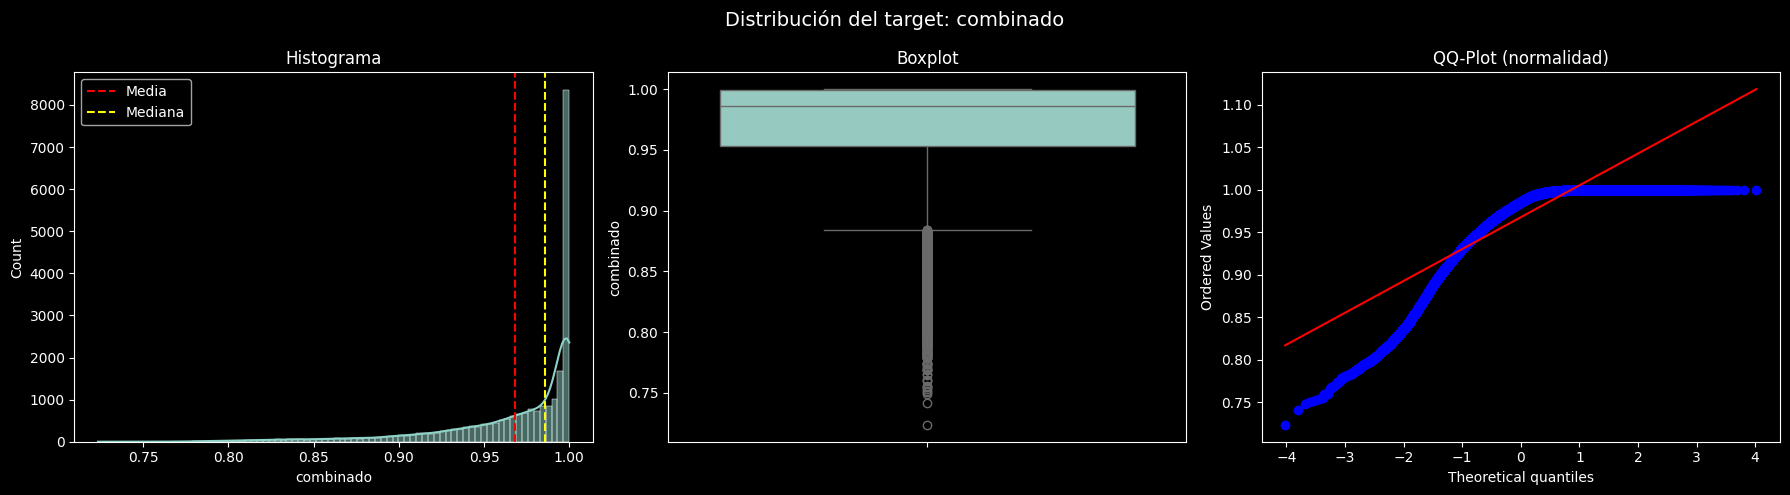

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Distribución del target: combinado", fontsize=14)

# Histograma + KDE
sns.histplot(df["combinado"], bins=80, kde=True, ax=axes[0])
axes[0].set_title("Histograma")
axes[0].axvline(df["combinado"].mean(), color="red", linestyle="--", label="Media")
axes[0].axvline(df["combinado"].median(), color="yellow", linestyle="--", label="Mediana")
axes[0].legend()

# Boxplot
sns.boxplot(y=df["combinado"], ax=axes[1])
axes[1].set_title("Boxplot")

# QQ-Plot — ¿es normal?
stats.probplot(df["combinado"], dist="norm", plot=axes[2])
axes[2].set_title("QQ-Plot (normalidad)")

plt.tight_layout()
plt.show()

# Hallazgos
Histograma

Se observa:

Gran acumulación cerca de 1

Lo cual era esperado.

Boxplot

Muchos puntos inferiores:

0.72
0.75
0.80

No necesariamente son errores.

Probablemente son:

JPEG Q10
WEBP Q10

que realmente generan baja calidad.

Por CRISP-DM:

NO eliminarlos todavía

porque son casos válidos.

QQPlot

Confirma:

No hay normalidad

pero eso NO es un problema para:

XGBoost
LightGBM
Random Forest
Conclusión

No hacer transformaciones sobre el target.

Mantener:

y = combinado

tal cual.

# Análisis de impacto de variables categóricas sobre la calidad perceptual

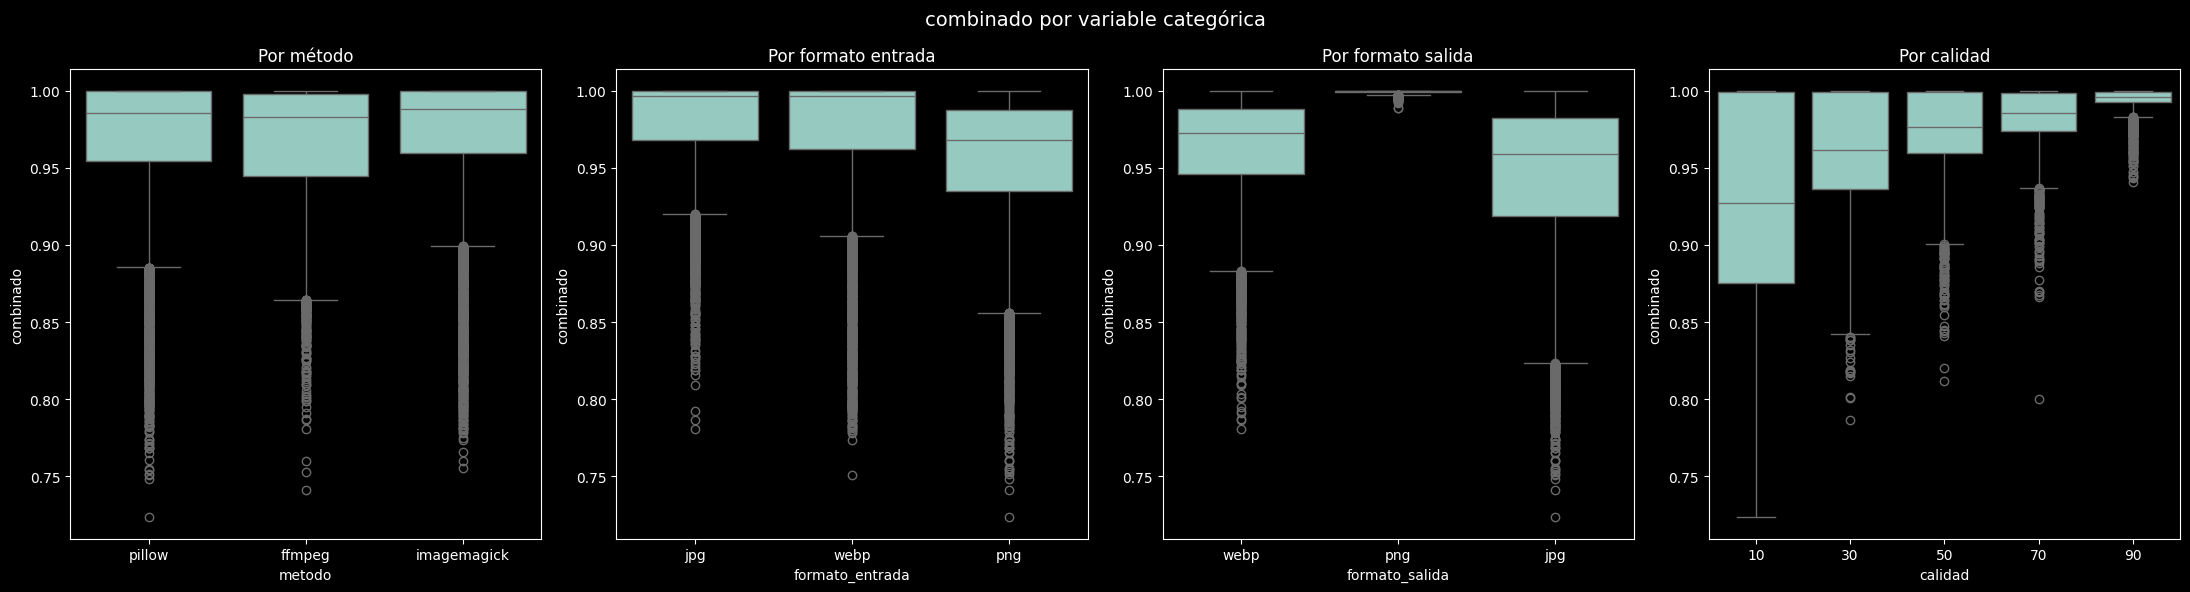


Media combinado por método:
metodo
ffmpeg         0.9663
imagemagick    0.9698
pillow         0.9676
Name: combinado, dtype: float64

Media combinado por formato de entrada:
formato_entrada
jpg     0.9789
png     0.9525
webp    0.9722
Name: combinado, dtype: float64

Media combinado por formato de salida:
formato_salida
jpg     0.9422
png     0.9994
webp    0.9621
Name: combinado, dtype: float64

Media combinado por calidad:
calidad
10    0.9261
30    0.9607
50    0.9737
70    0.9828
90    0.9945
Name: combinado, dtype: float64


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
fig.suptitle("combinado por variable categórica", fontsize=14)

sns.boxplot(data=df, x="metodo",          y="combinado", ax=axes[0])
axes[0].set_title("Por método")

sns.boxplot(data=df, x="formato_entrada", y="combinado", ax=axes[1])
axes[1].set_title("Por formato entrada")

sns.boxplot(data=df, x="formato_salida",  y="combinado", ax=axes[2])
axes[2].set_title("Por formato salida")

sns.boxplot(data=df, x="calidad",         y="combinado", ax=axes[3])
axes[3].set_title("Por calidad")

plt.tight_layout()
plt.show()

print("\nMedia combinado por método:")
print(df.groupby("metodo")["combinado"].mean().round(4))

print("\nMedia combinado por formato de entrada:")
print(df.groupby("formato_entrada")["combinado"].mean().round(4))

print("\nMedia combinado por formato de salida:")
print(df.groupby("formato_salida")["combinado"].mean().round(4))

print("\nMedia combinado por calidad:")
print(df.groupby("calidad")["combinado"].mean().round(4))

# Resultados
Método
imagemagick = 0.9698
pillow      = 0.9676
ffmpeg      = 0.9663

Diferencias pequeñas.

Formato entrada
jpg  = 0.9789
webp = 0.9722
png  = 0.9525

Interesante.

Las imágenes PNG son las más sensibles a la compresión.

Formato salida
png = 0.9994
jpg = 0.9422
webp= 0.9621

Esto es MUY importante.

Significa que:

formato_salida

es una feature muy relevante.

Calidad
10 → 0.926
30 → 0.961
50 → 0.973
70 → 0.982
90 → 0.994

Perfectamente monotónica.

Excelente señal.

Conclusión

Mantener:

metodo
formato_entrada
formato_salida
calidad


# Correlación lineal entre atributos originales y calidad perceptual

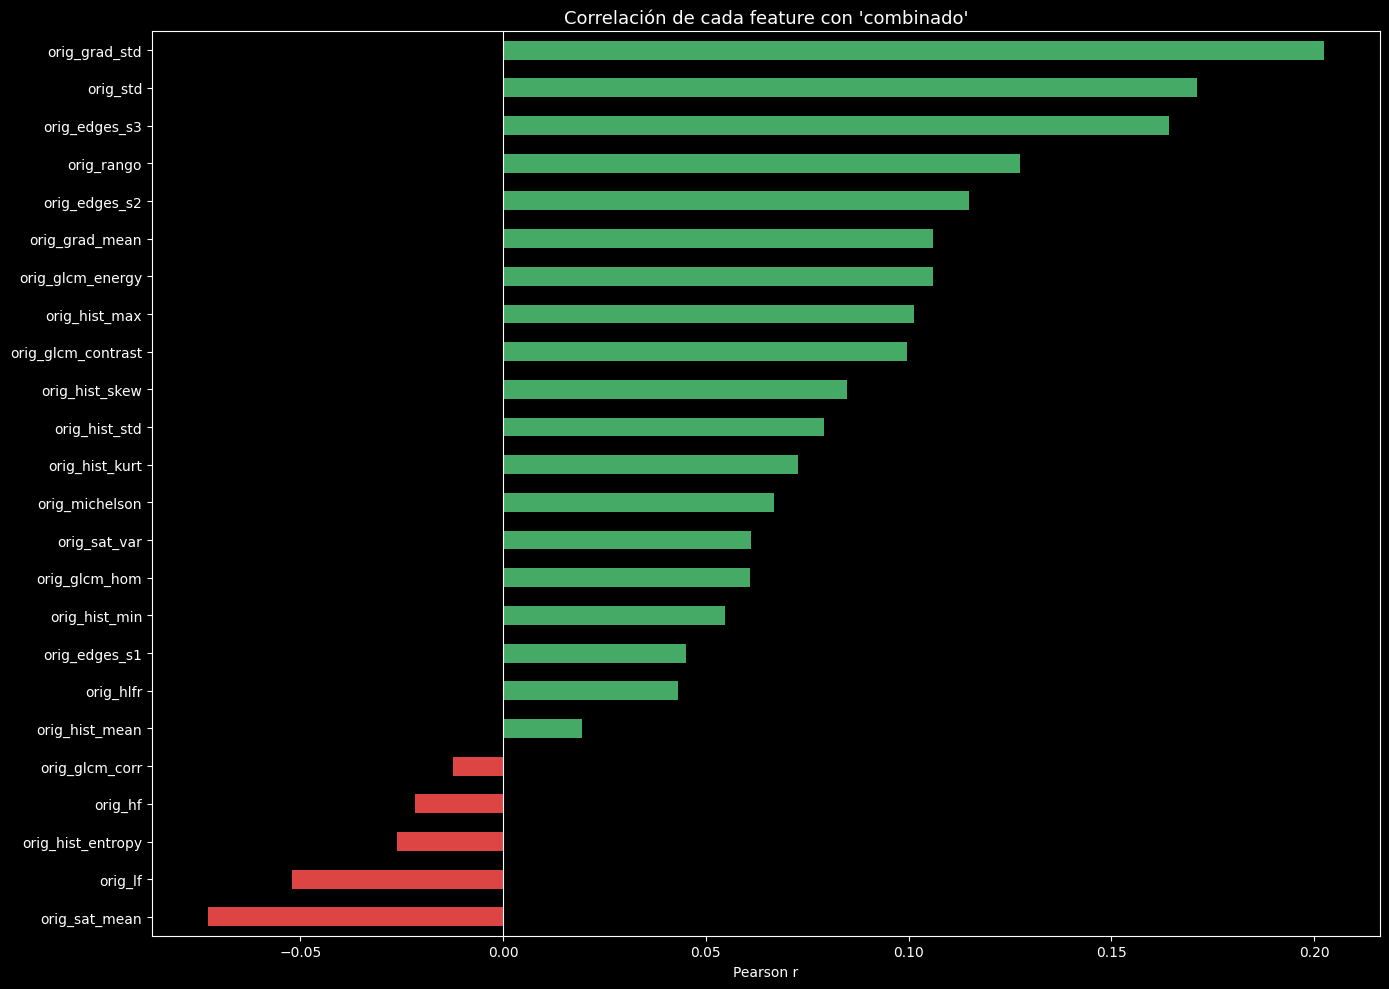


Top 10 más correlacionadas:
orig_grad_std         0.202497
orig_std              0.171226
orig_edges_s3         0.164108
orig_rango            0.127558
orig_edges_s2         0.114847
orig_grad_mean        0.106130
orig_glcm_energy      0.105990
orig_hist_max         0.101257
orig_glcm_contrast    0.099535
orig_hist_skew        0.084907
dtype: float64


In [9]:
# Solo columnas numéricas float64
feat_cols = [c for c in df.select_dtypes("float64").columns
             if c not in ["ms_ssim", "lpips_raw", "lpips_norm", "combinado"]]

correlaciones = df[feat_cols].corrwith(df["combinado"]).sort_values()

plt.figure(figsize=(14, 10))
correlaciones.plot(kind="barh", color=[
    "#DD4444" if v < 0 else "#44AA66" for v in correlaciones
])
plt.axvline(0, color="white", linewidth=0.8)
plt.title("Correlación de cada feature con 'combinado'", fontsize=13)
plt.xlabel("Pearson r")
plt.tight_layout()
plt.show()

print("\nTop 10 más correlacionadas:")
print(correlaciones.abs().sort_values(ascending=False).head(10))

Top:

orig_grad_std
orig_std
orig_edges_s3
orig_rango

pero:

r máximo = 0.20

Muy bajo.

Interpretación

Esto NO significa que las features sean malas.

Significa:

La relación NO es lineal.

Justamente:

XGBoost

es bueno capturando relaciones no lineales.

# Análisis de correlación entre atributos predictivos

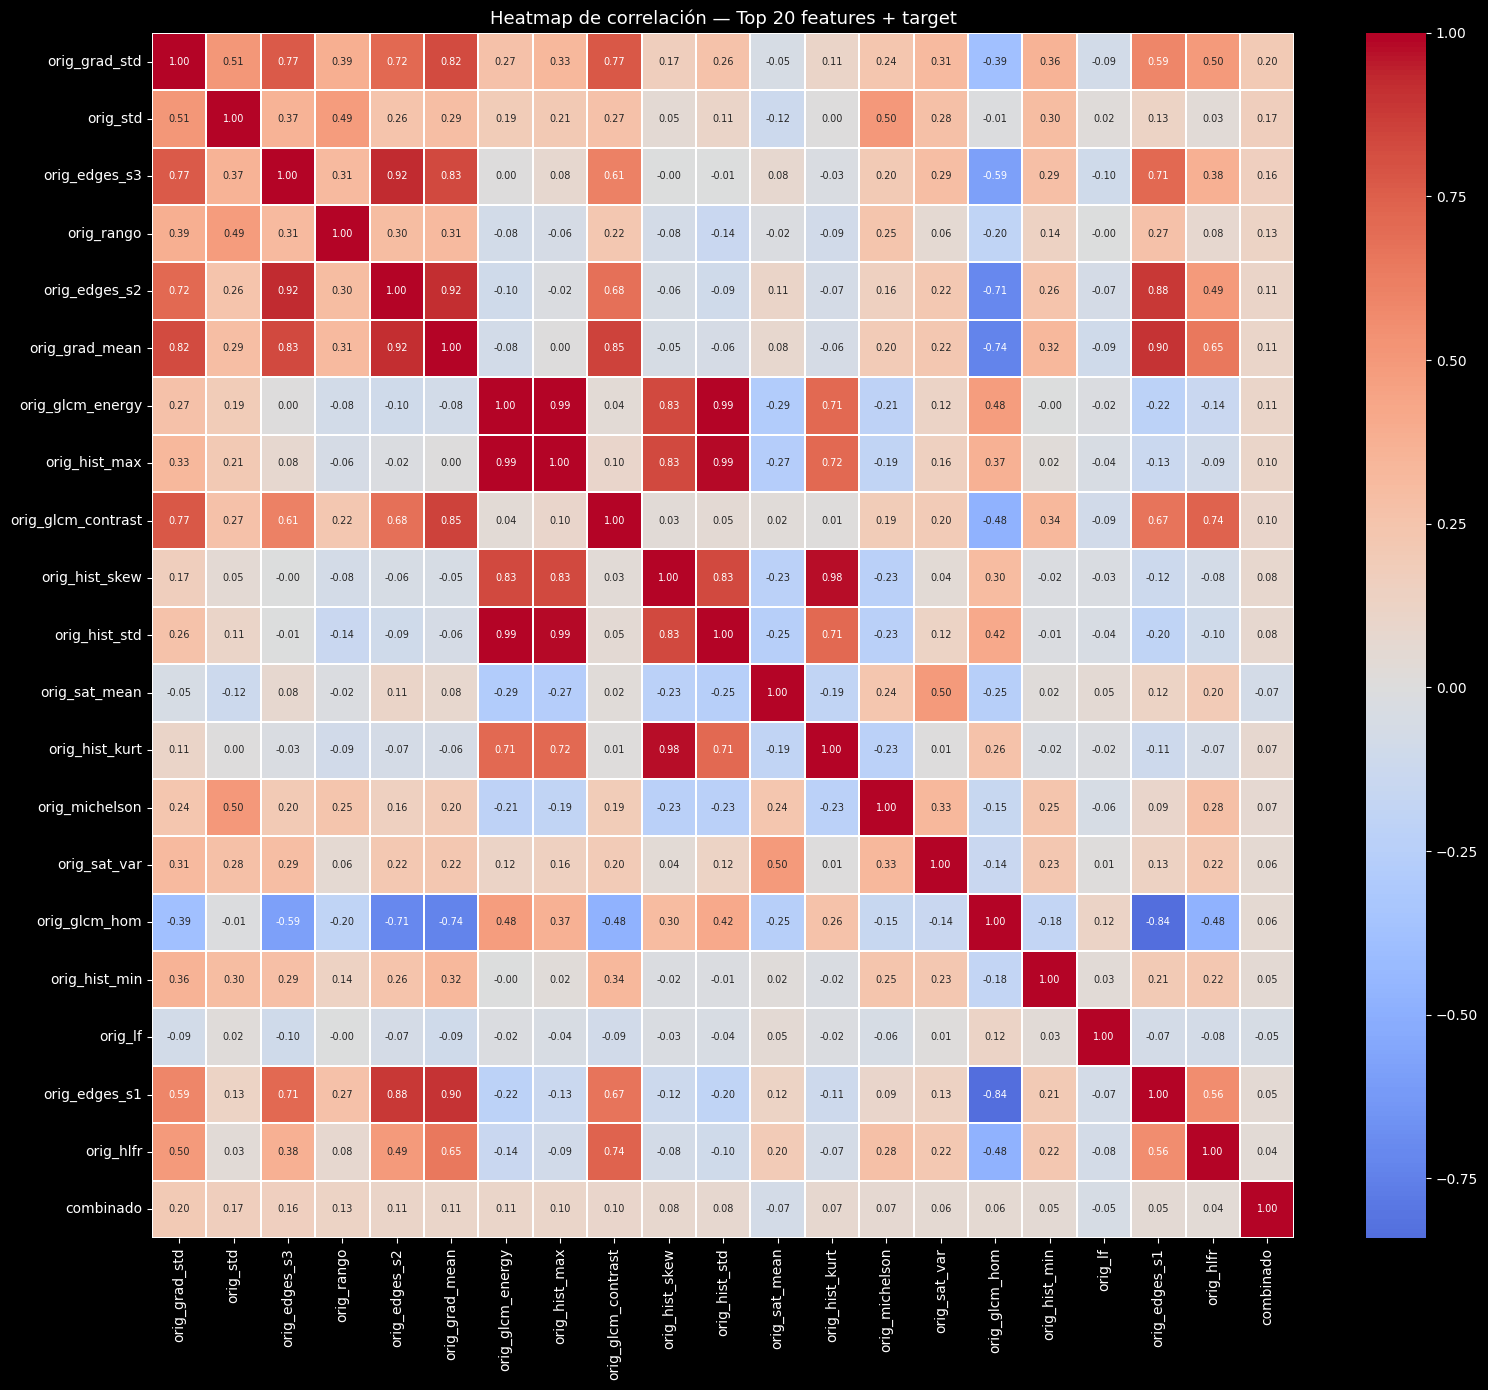

In [10]:
# Seleccionar features más relevantes para no saturar el heatmap
top_feats = correlaciones.abs().sort_values(ascending=False).head(20).index.tolist()
top_feats += ["combinado"]

corr_matrix = df[top_feats].corr()

plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    annot_kws={"size": 7}
)
plt.title("Heatmap de correlación — Top 20 features + target", fontsize=13)
plt.tight_layout()
plt.show()

quí encontré el primer problema real.

Observa:

orig_glcm_energy ↔ orig_hist_max
r = 0.99

También:

orig_edges_s2 ↔ orig_grad_mean
r = 0.92
orig_edges_s3 ↔ orig_edges_s2
r = 0.92
orig_hist_skew ↔ orig_hist_kurt
r = 0.98
Conclusión

Hay redundancia.

No es grave para XGBoost.

Pero sí para:

Regresión
MLP

# Evaluación de distribución y escalamiento de atributos originales

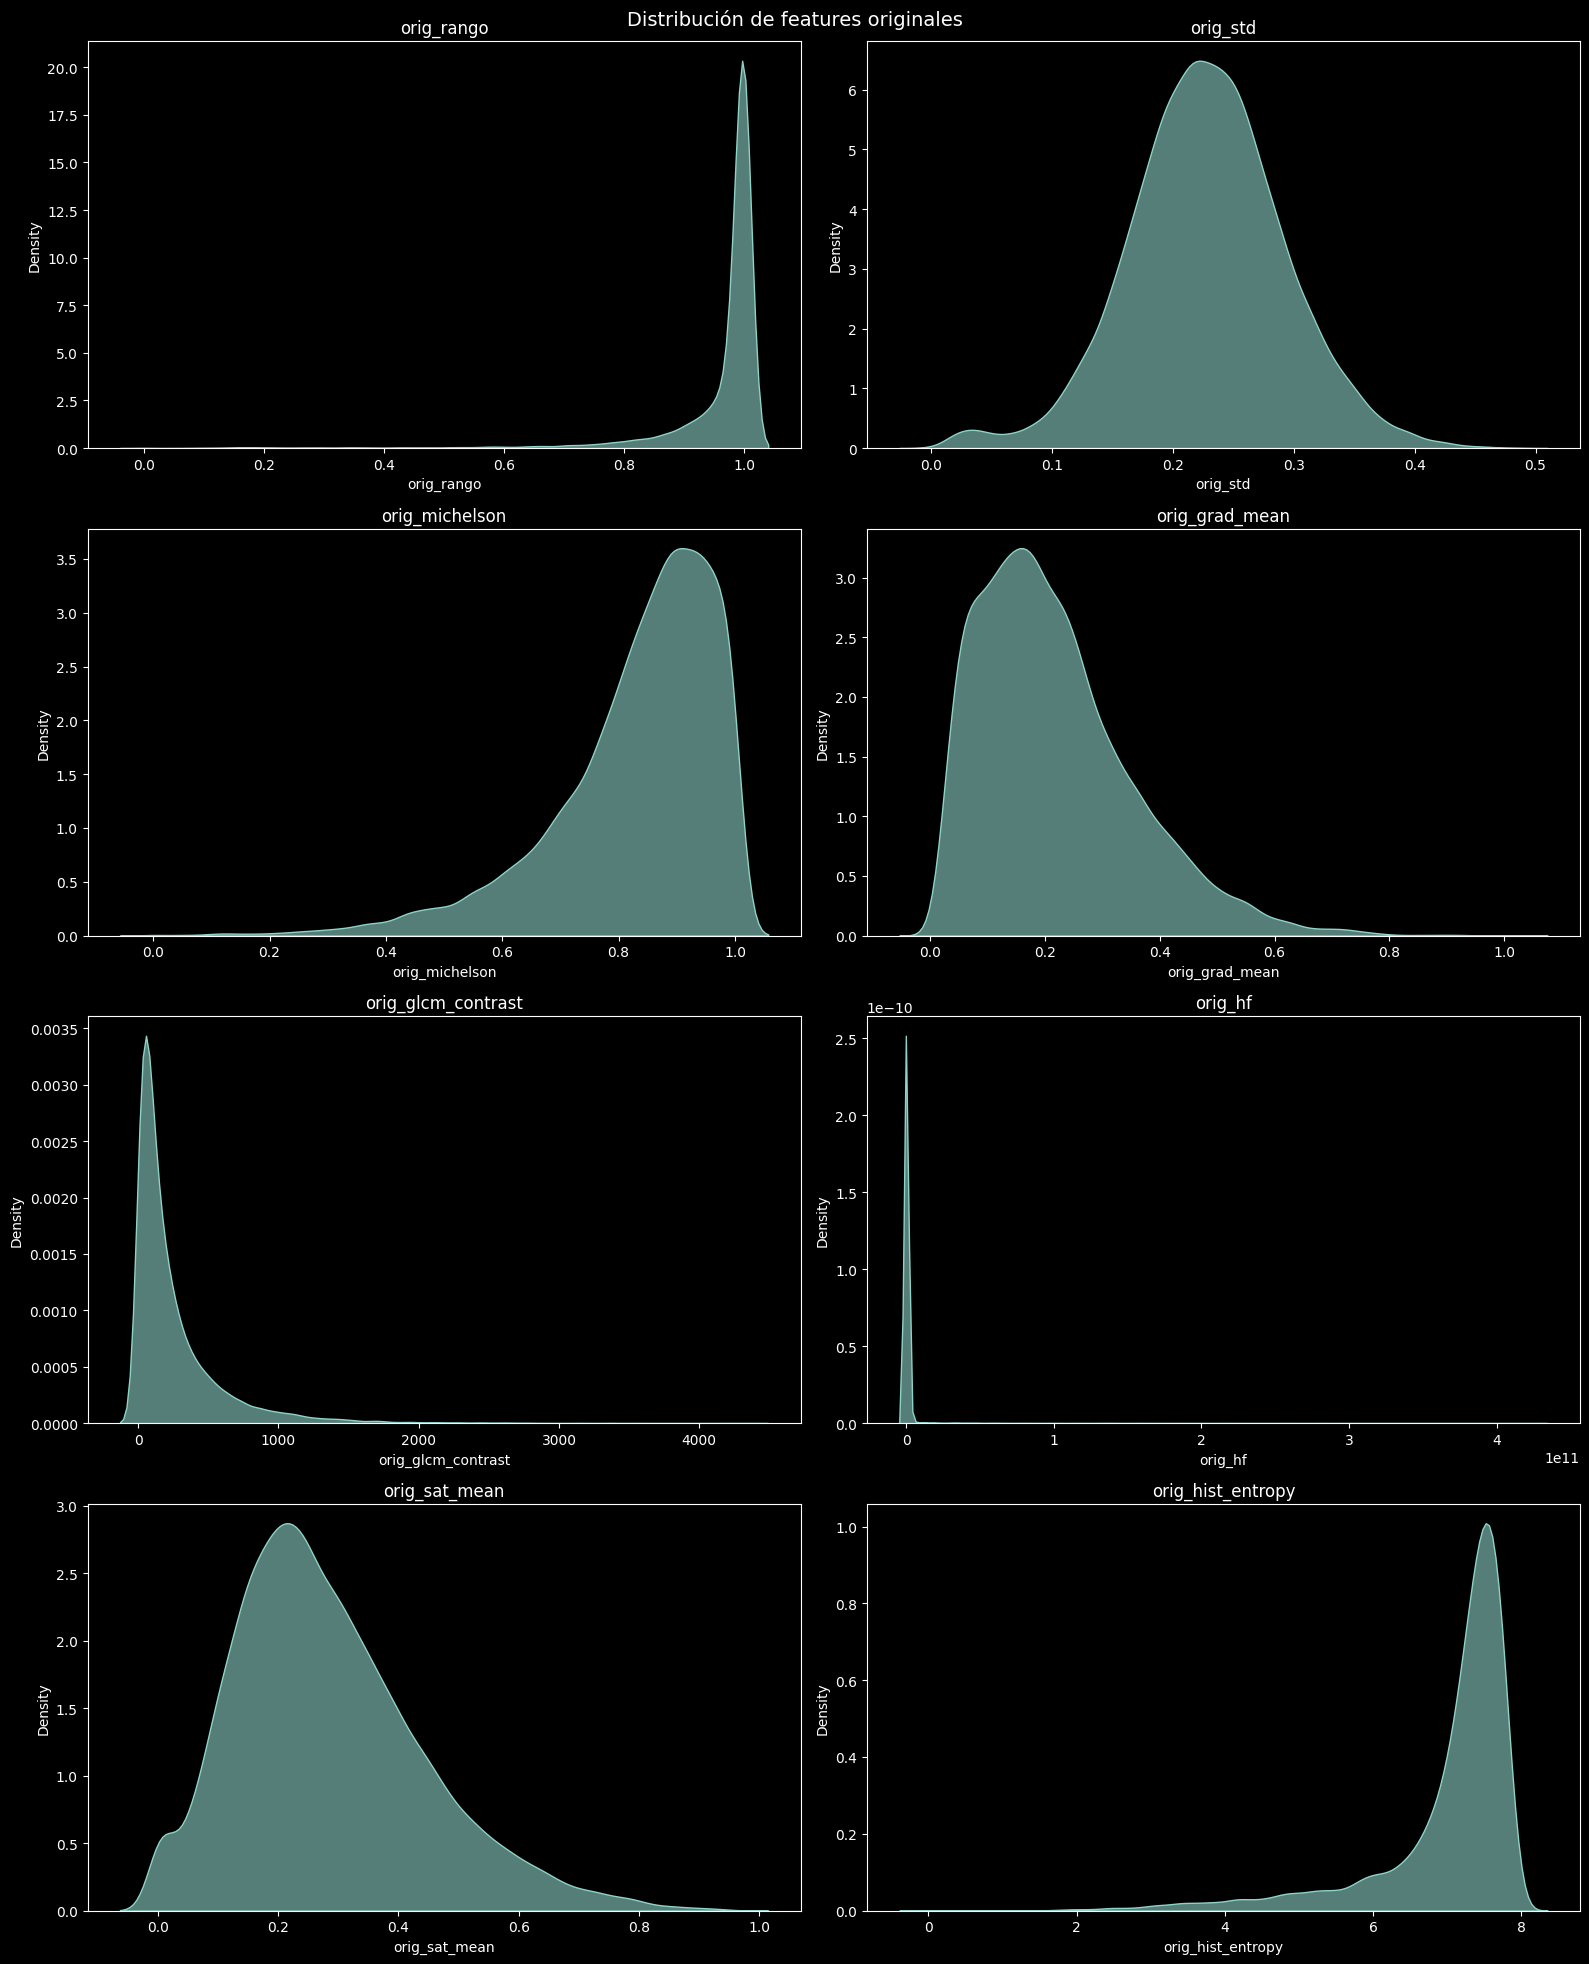

In [12]:
# Reemplazar por distribución de features originales solamente
features_ver = [
    "orig_rango", "orig_std", "orig_michelson", "orig_grad_mean",
    "orig_glcm_contrast", "orig_hf", "orig_sat_mean", "orig_hist_entropy"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
fig.suptitle("Distribución de features originales", fontsize=14)

for ax, f in zip(axes.flat, features_ver):
    sns.kdeplot(df[f], ax=ax, fill=True, alpha=0.6)
    ax.set_title(f)

plt.tight_layout()
plt.show()

Aquí aparece otro problema.

Variables:

orig_hf
orig_lf
orig_glcm_contrast

tienen colas enormes.

Ejemplo:

orig_hf

va desde:

0
hasta
4.3e11

Eso es brutal.

Recomendación

Transformación logarítmica:

np.log1p()

para:

orig_hf
orig_lf
orig_glcm_contrast
orig_hist_max
orig_glcm_energy

# Detección de valores extremos mediante Z-score

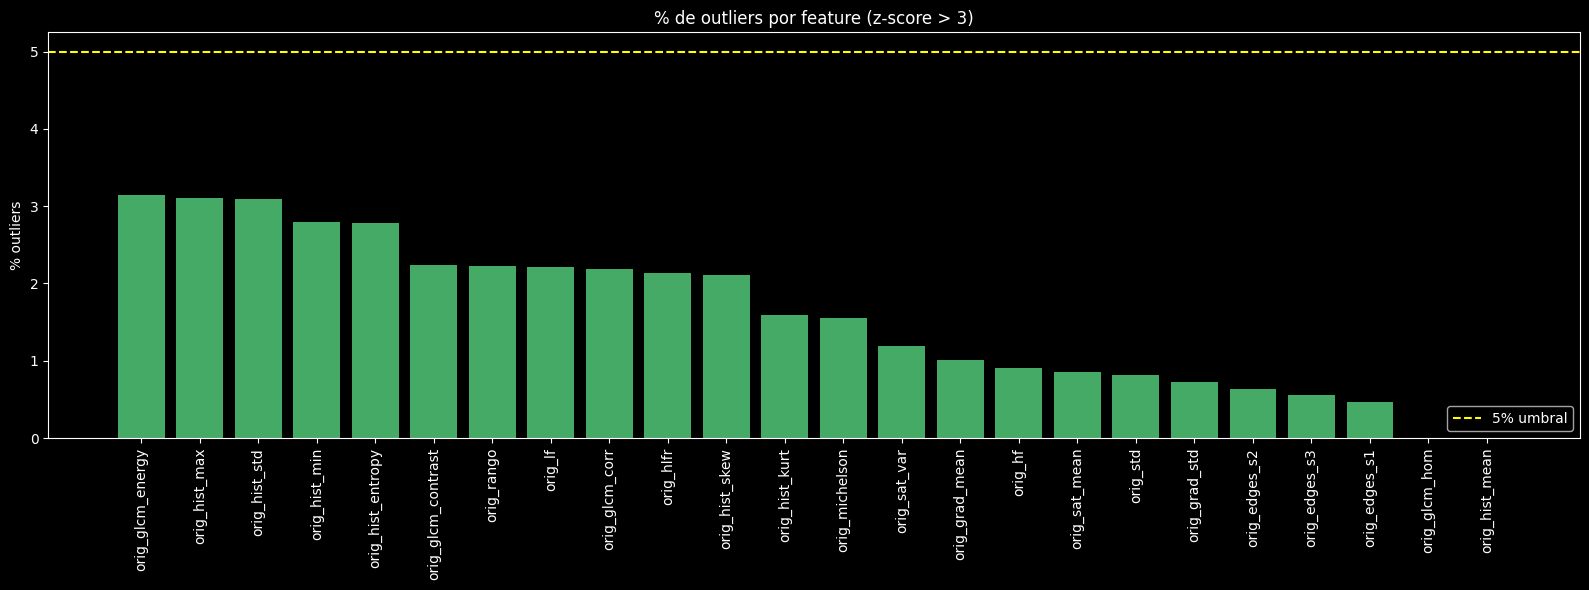


Features con más del 5% de outliers:
Empty DataFrame
Columns: [feature, n_outliers, pct]
Index: []


In [13]:
# Excluir columnas objeto y targets — solo features numéricas de entrada
feat_cols_num = [c for c in df.select_dtypes("float64").columns
                 if c not in ["ms_ssim", "lpips_raw", "lpips_norm", "combinado"]]

outliers_resumen = []

for col in feat_cols_num:
    z = np.abs(stats.zscore(df[col]))
    n_outliers = (z > 3).sum()
    outliers_resumen.append({"feature": col, "n_outliers": n_outliers,
                             "pct": round(n_outliers / len(df) * 100, 2)})

df_out = pd.DataFrame(outliers_resumen).sort_values("n_outliers", ascending=False)

plt.figure(figsize=(16, 6))
plt.bar(df_out["feature"], df_out["pct"],
        color=["#DD4444" if v > 5 else "#44AA66" for v in df_out["pct"]])
plt.xticks(rotation=90)
plt.axhline(5, color="yellow", linestyle="--", label="5% umbral")
plt.title("% de outliers por feature (z-score > 3)")
plt.ylabel("% outliers")
plt.legend()
plt.tight_layout()
plt.show()

print("\nFeatures con más del 5% de outliers:")
print(df_out[df_out["pct"] > 5])

Resultado:

Ninguna variable supera 5%

Excelente.

Importante

NO eliminar outliers todavía.

Porque:

son características reales de imágenes

No son errores de captura.

# Verificación de valores faltantes (Missing Values)

In [14]:
na = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

print(na[na > 0])

Series([], dtype: int64)


No se encontraron valores nulos en ninguna de las 37 variables del dataset.

# Detección de variables constantes

In [15]:
constantes = []

for c in df.columns:
    if df[c].nunique() <= 1:
        constantes.append(c)

print(constantes)

['orig_hist_bins']


# Interpretación

La variable:

orig_hist_bins

presenta exactamente el mismo valor en los 23.993 registros.

Por lo tanto:

No aporta capacidad predictiva.
No contribuye a diferenciar imágenes.
Su importancia para cualquier modelo será nula.

Desde el punto de vista estadístico:

Varianza = 0
Información aportada = 0
Conclusión

La variable:

orig_hist_bins

debe eliminarse durante la fase de preparación de datos.

# Detección de baja varianza (Variance Threshold)

In [16]:
cols_num = df.select_dtypes(include=["float64", "int64"]).columns

varianzas = (
    df[cols_num]
    .var()
    .sort_values()
)

print(varianzas.head(15))

orig_hist_mean    9.579478e-34
orig_hist_kurt    1.885901e-08
orig_hist_skew    3.677189e-08
orig_hist_min     3.921591e-08
orig_hist_std     6.355509e-05
orig_hlfr         1.032098e-04
orig_edges_s3     3.088088e-04
ms_ssim           4.830552e-04
orig_sat_var      9.216232e-04
orig_edges_s2     9.222627e-04
combinado         1.854275e-03
orig_glcm_corr    2.368743e-03
orig_edges_s1     4.160521e-03
orig_std          4.237463e-03
lpips_norm        4.287529e-03
dtype: float64


# Limpiar el dataset

Conclusión de la exploración
Lo que NO debemos hacer

❌ Eliminar filas por outliers.

Razones:

Ninguna variable supera el 5% de outliers.
Son métricas visuales reales de imágenes.
XGBoost y Random Forest son robustos a outliers.
El target tiene una distribución naturalmente sesgada hacia 1.

❌ Transformar el target combinado.

Razones:

Está acotado entre 0 y 1.
Es interpretable.
Tu objetivo es predecir calidad perceptual.
Lo que SÍ debemos hacer
1. Eliminar columnas sin información

Tu análisis de varianza mostró:

orig_hist_mean    9.57e-34
orig_hist_kurt    1.88e-08
orig_hist_skew    3.67e-08
orig_hist_min     3.92e-08
orig_hist_std     6.35e-05
orig_hlfr         1.03e-04

Las primeras 5 prácticamente son constantes.

2. Eliminar columnas tipo lista

Encontraste:

['orig_hist_bins']

y además:

orig_hist
orig_hist_norm
orig_hist_bins

son objetos.

No sirven para XGBoost.

3. Corregir distribuciones extremadamente asimétricas

Según tus KDE:

Variables problemáticas:

orig_hf
orig_lf
orig_glcm_contrast
orig_glcm_energy
orig_hist_max

Estas deberían recibir:

np.log1p()
4. Revisar colinealidad extrema

En el heatmap encontré:

orig_glcm_energy ↔ orig_hist_max = 0.99
orig_glcm_energy ↔ orig_hist_std = 0.99
orig_edges_s2 ↔ orig_grad_mean = 0.92
orig_edges_s2 ↔ orig_edges_s3 = 0.92

Correlaciones mayores a:

|r| > 0.95

deberían eliminarse.

Aunque XGBoost lo soporta, simplifica el modelo.

# Eliminar columnas inútiles

In [17]:
def limpiar_columnas_inutiles(df):
    
    columnas_eliminar = [
        "img_original",
        "img_recodificada",
        "orig_hist",
        "orig_hist_norm",
        "orig_hist_bins",
        "ms_ssim",
        "lpips_raw",
        "lpips_norm"
    ]

    cols_existentes = [
        c for c in columnas_eliminar
        if c in df.columns
    ]

    df = df.drop(columns=cols_existentes)

    print(f"Columnas eliminadas: {len(cols_existentes)}")

    return df

# eliminar variables casi constantes

In [18]:
def eliminar_baja_varianza(df, threshold=1e-4):

    num_cols = df.select_dtypes(include=np.number).columns

    varianzas = df[num_cols].var()

    eliminar = varianzas[
        varianzas < threshold
    ].index.tolist()

    print("Variables eliminadas:")
    print(eliminar)

    return df.drop(columns=eliminar)

log transform

In [19]:
def aplicar_log_transform(df):

    cols_log = [
        "orig_hf",
        "orig_lf",
        "orig_glcm_contrast",
        "orig_glcm_energy",
        "orig_hist_max"
    ]

    for col in cols_log:

        if col in df.columns:

            df[f"{col}_log"] = np.log1p(df[col])

            df.drop(columns=col,
                    inplace=True)

            print(f"{col} → {col}_log")

    return df

# eliminar alta colinealidad

In [20]:
def eliminar_colinealidad(
        df,
        threshold=0.95,
        target="combinado"
    ):

    numericas = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    numericas.remove(target)

    corr = (
        df[numericas]
        .corr()
        .abs()
    )

    upper = corr.where(
        np.triu(
            np.ones(corr.shape),
            k=1
        ).astype(bool)
    )

    eliminar = [
        column
        for column in upper.columns
        if any(upper[column] > threshold)
    ]

    print("Variables eliminadas:")
    print(eliminar)

    return df.drop(columns=eliminar)

# codificar categóricas

In [21]:
def codificar_categoricas(df):

    categoricas = [
        "metodo",
        "formato_entrada",
        "formato_salida"
    ]

    df = pd.get_dummies(
        df,
        columns=categoricas,
        drop_first=True
    )

    return df

In [22]:
def eliminar_metricas_target(df):

    cols_eliminar = [
        "ms_ssim",
        "lpips_raw",
        "lpips_norm"
    ]

    cols_existentes = [
        c for c in cols_eliminar
        if c in df.columns
    ]

    df = df.drop(columns=cols_existentes)

    print("Columnas eliminadas:")
    print(cols_existentes)

    return df

# Pipeline completo de limpieza

In [23]:
df_clean = df.copy()

df_clean = limpiar_columnas_inutiles(df_clean)

df_clean = eliminar_baja_varianza(
    df_clean,
    threshold=1e-4
)

df_clean = aplicar_log_transform(
    df_clean
)

df_clean = eliminar_colinealidad(
    df_clean,
    threshold=0.95
)

df_clean = codificar_categoricas(
    df_clean
)

print(df_clean.shape)

Columnas eliminadas: 8
Variables eliminadas:
['orig_hist_std', 'orig_hist_mean', 'orig_hist_min', 'orig_hist_skew', 'orig_hist_kurt']
orig_hf → orig_hf_log
orig_lf → orig_lf_log
orig_glcm_contrast → orig_glcm_contrast_log
orig_glcm_energy → orig_glcm_energy_log
orig_hist_max → orig_hist_max_log
Variables eliminadas:
['orig_hist_max_log']
(23993, 26)


In [25]:
print(df_clean.isnull().sum().sum())

0


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23993 entries, 0 to 23992
Data columns (total 34 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   img_original        23993 non-null  object 
 1   img_recodificada    23993 non-null  object 
 2   metodo              23993 non-null  object 
 3   formato_entrada     23993 non-null  object 
 4   formato_salida      23993 non-null  object 
 5   calidad             23993 non-null  int64  
 6   orig_rango          23993 non-null  float64
 7   orig_std            23993 non-null  float64
 8   orig_michelson      23993 non-null  float64
 9   orig_hf             23993 non-null  float64
 10  orig_lf             23993 non-null  float64
 11  orig_hlfr           23993 non-null  float64
 12  orig_edges_s1       23993 non-null  float64
 13  orig_edges_s2       23993 non-null  float64
 14  orig_edges_s3       23993 non-null  float64
 15  orig_grad_mean      23993 non-null  float64
 16  orig

In [27]:
df.to_csv("csv/dataset_limpio.csv", index=False)

In [28]:
df.head()

,img_original,img_recodificada,metodo,formato_entrada,formato_salida,calidad,orig_rango,orig_std,orig_michelson,orig_hf,...,orig_hist_norm,orig_hist_bins,orig_hist_entropy,orig_hist_std,orig_hist_mean,orig_hist_min,orig_hist_max,orig_hist_skew,orig_hist_kurt,combinado
0,imagenes\jpg\COCO_test2014_000000000057.jpg,imagenes\pillow\webp\COCO_test2014_00000000005...,pillow,jpg,webp,10,0.999435,0.097696,0.538516,73970180.0,...,"[7.684426229508197e-05, 5.122950819672131e-05,...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",6.114273,0.008382,0.003906,0.000004,0.035802,1.600125e-06,4.567225e-08,0.832252
1,imagenes\jpg\COCO_test2014_000000000080.jpg,imagenes\ffmpeg\webp\COCO_test2014_00000000008...,ffmpeg,jpg,webp,10,0.996890,0.219220,0.878967,127894710.0,...,"[0.00025980679156908666, 0.0002232142857142857...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",7.524005,0.002784,0.003906,0.000000,0.008519,-4.964806e-10,1.037467e-10,0.902257
2,imagenes\jpg\COCO_test2014_000000000090.jpg,imagenes\imagemagick\webp\COCO_test2014_000000...,imagemagick,jpg,webp,50,0.996324,0.181743,0.684643,95682910.0,...,"[7.284382284382284e-06, 3.642191142191142e-06,...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",7.426530,0.003709,0.003906,0.000000,0.018378,8.682542e-08,1.095188e-09,0.951452
3,imagenes\jpg\COCO_test2014_000000000155.jpg,imagenes\pillow\webp\COCO_test2014_00000000015...,pillow,jpg,webp,30,0.999167,0.289328,0.828561,48832212.0,...,"[4.3911007025761124e-05, 0.0001427107728337236...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",7.718100,0.002594,0.003906,0.000044,0.016404,2.999470e-08,3.370706e-10,0.935868
4,imagenes\jpg\COCO_test2014_000000000171.jpg,imagenes\ffmpeg\webp\COCO_test2014_00000000017...,ffmpeg,jpg,webp,30,1.000000,0.134279,1.000000,33372866.0,...,"[0.16302637889688248, 0.2921390887290168, 0.12...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",4.172597,0.022989,0.003906,0.000000,0.292139,1.186514e-04,3.048955e-05,0.969250


# Normalizacion

In [29]:
from sklearn.preprocessing import StandardScaler
import joblib

def normalizar_dataset(df):

    df_norm = df.copy()

    # No escalar target
    # No escalar variables dummy

    cols_escalar = [
        c for c in df_norm.columns
        if c != "combinado"
        and not c.startswith("metodo_")
        and not c.startswith("formato_")
    ]

    scaler = StandardScaler()

    df_norm[cols_escalar] = scaler.fit_transform(
        df_norm[cols_escalar]
    )

    joblib.dump(
        scaler,
        "modelos/scaler.pkl"
    )

    print("=" * 50)
    print("NORMALIZACIÓN")
    print("=" * 50)
    print(f"Columnas escaladas: {len(cols_escalar)}")
    print(f"Scaler guardado: modelos/scaler.pkl")

    return df_norm, scaler

In [30]:
def convertir_bool_a_int(df):
    """
    Convierte todas las columnas booleanas del DataFrame
    a enteros (0 y 1).

    Parameters
    ----------
    df : pd.DataFrame

    Returns
    -------
    pd.DataFrame
    """

    cols_bool = df.select_dtypes(include="bool").columns.tolist()

    print("=" * 60)
    print("CONVERSIÓN BOOL → INT")
    print("=" * 60)

    if len(cols_bool) == 0:
        print("⚠ No se encontraron columnas booleanas")
        return df

    print(f"Columnas encontradas: {len(cols_bool)}")
    print(cols_bool)

    df[cols_bool] = df[cols_bool].astype(int)

    print("\n✅ Conversión completada")
    print(df[cols_bool].dtypes)

    return df

In [31]:
df_norm, scaler = normalizar_dataset(df_clean)

df_norm.describe().T[
    ["mean", "std"]
].head(15)

NORMALIZACIÓN
Columnas escaladas: 19
Scaler guardado: modelos/scaler.pkl


,mean,std
calidad,-5.301011e-17,1.000021
orig_rango,1.611033e-16,1.000021
orig_std,-3.222067e-16,1.000021
orig_michelson,1.516267e-16,1.000021
orig_hlfr,3.790667e-17,1.000021
orig_edges_s1,-1.421500e-16,1.000021
orig_edges_s2,-1.421500e-16,1.000021
orig_edges_s3,1.421500e-16,1.000021
orig_grad_mean,-9.476667e-18,1.000021
orig_grad_std,-2.369167e-16,1.000021


In [32]:
df_norm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23993 entries, 0 to 23992
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   calidad                 23993 non-null  float64
 1   orig_rango              23993 non-null  float64
 2   orig_std                23993 non-null  float64
 3   orig_michelson          23993 non-null  float64
 4   orig_hlfr               23993 non-null  float64
 5   orig_edges_s1           23993 non-null  float64
 6   orig_edges_s2           23993 non-null  float64
 7   orig_edges_s3           23993 non-null  float64
 8   orig_grad_mean          23993 non-null  float64
 9   orig_grad_std           23993 non-null  float64
 10  orig_glcm_hom           23993 non-null  float64
 11  orig_glcm_corr          23993 non-null  float64
 12  orig_sat_mean           23993 non-null  float64
 13  orig_sat_var            23993 non-null  float64
 14  orig_hist_entropy       23993 non-null

In [33]:
df_norm = convertir_bool_a_int(df_norm)

CONVERSIÓN BOOL → INT
Columnas encontradas: 6
['metodo_imagemagick', 'metodo_pillow', 'formato_entrada_png', 'formato_entrada_webp', 'formato_salida_png', 'formato_salida_webp']

✅ Conversión completada
metodo_imagemagick      int64
metodo_pillow           int64
formato_entrada_png     int64
formato_entrada_webp    int64
formato_salida_png      int64
formato_salida_webp     int64
dtype: object


In [34]:
df_norm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23993 entries, 0 to 23992
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   calidad                 23993 non-null  float64
 1   orig_rango              23993 non-null  float64
 2   orig_std                23993 non-null  float64
 3   orig_michelson          23993 non-null  float64
 4   orig_hlfr               23993 non-null  float64
 5   orig_edges_s1           23993 non-null  float64
 6   orig_edges_s2           23993 non-null  float64
 7   orig_edges_s3           23993 non-null  float64
 8   orig_grad_mean          23993 non-null  float64
 9   orig_grad_std           23993 non-null  float64
 10  orig_glcm_hom           23993 non-null  float64
 11  orig_glcm_corr          23993 non-null  float64
 12  orig_sat_mean           23993 non-null  float64
 13  orig_sat_var            23993 non-null  float64
 14  orig_hist_entropy       23993 non-null

In [35]:
from sklearn.model_selection import train_test_split

X = df_norm.drop(columns=["combinado"])
y = df_norm["combinado"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

In [36]:
import joblib

# Guardar datasets
X_train.to_csv("csv/X_train.csv", index=False)
X_val.to_csv("csv/X_val.csv", index=False)
X_test.to_csv("csv/X_test.csv", index=False)

y_train.to_csv("csv/y_train.csv", index=False)
y_val.to_csv("csv/y_val.csv", index=False)
y_test.to_csv("csv/y_test.csv", index=False)

print("✅ Datasets guardados")

✅ Datasets guardados


In [37]:
from sklearn.preprocessing import StandardScaler

cols_escalar = X_train.select_dtypes(include=["float64", "int64"]).columns

scaler = StandardScaler()

X_train[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_val[cols_escalar] = scaler.transform(X_val[cols_escalar])
X_test[cols_escalar] = scaler.transform(X_test[cols_escalar])

joblib.dump(scaler, "csv/scaler.pkl")

print("✅ Scaler guardado")

✅ Scaler guardado


In [38]:
print("=" * 60)
print("RESUMEN FINAL — PREPARACIÓN DE DATOS")
print("=" * 60)

print(f"Filas totales:           {len(df_norm):,}")
print(f"Features finales:        {X.shape[1]}")
print(f"Target:                  combinado")

print("\nTARGET")
print("-" * 60)
print(f"Rango:                   [{y.min():.6f}, {y.max():.6f}]")
print(f"Media:                   {y.mean():.6f}")
print(f"Desv. estándar:          {y.std():.6f}")

print("\nCALIDAD DE DATOS")
print("-" * 60)
print(f"Nulos totales:           {df_norm.isnull().sum().sum()}")
print(f"Duplicados:              {df_norm.duplicated().sum()}")

print("\nTIPOS DE DATOS")
print("-" * 60)
print(df_norm.dtypes.value_counts())

print("\nSPLIT")
print("-" * 60)
print(f"Train:                   {len(X_train):,} ({len(X_train)/len(df_norm)*100:.1f}%)")
print(f"Validation:              {len(X_val):,} ({len(X_val)/len(df_norm)*100:.1f}%)")
print(f"Test:                    {len(X_test):,} ({len(X_test)/len(df_norm)*100:.1f}%)")

print("\nFEATURES FINALES")
print("-" * 60)

for i, col in enumerate(X.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nTOTAL FEATURES:")
print(len(X.columns))

print("=" * 60)

RESUMEN FINAL — PREPARACIÓN DE DATOS
Filas totales:           23,993
Features finales:        25
Target:                  combinado

TARGET
------------------------------------------------------------
Rango:                   [0.723542, 1.000000]
Media:                   0.967890
Desv. estándar:          0.043061

CALIDAD DE DATOS
------------------------------------------------------------
Nulos totales:           0
Duplicados:              18

TIPOS DE DATOS
------------------------------------------------------------
float64    20
int64       6
Name: count, dtype: int64

SPLIT
------------------------------------------------------------
Train:                   16,795 (70.0%)
Validation:              3,599 (15.0%)
Test:                    3,599 (15.0%)

FEATURES FINALES
------------------------------------------------------------
01. calidad
02. orig_rango
03. orig_std
04. orig_michelson
05. orig_hlfr
06. orig_edges_s1
07. orig_edges_s2
08. orig_edges_s3
09. orig_grad_mean
10. orig_

In [39]:
print("=" * 60)
print("READY FOR ML")
print("=" * 60)

solo_numericas = all(
    str(t) != "object"
    for t in X.dtypes
)

print(f"Solo variables numéricas: {solo_numericas}")
print(f"Sin NaN:                  {X.isnull().sum().sum() == 0}")
print(f"Sin infinitos:            {np.isinf(X.values).sum() == 0}")

if (
    solo_numericas
    and X.isnull().sum().sum() == 0
    and np.isinf(X.values).sum() == 0
):
    print("\n✅ Dataset listo para entrenamiento")
else:
    print("\n❌ Revisar dataset")

READY FOR ML
Solo variables numéricas: True
Sin NaN:                  True
Sin infinitos:            True

✅ Dataset listo para entrenamiento
